# Long CoT 복습과제 — 내용이 틀릴 때와 구조가 틀릴 때

**논문**: Li et al., *Language Models Can Easily Learn to Reason from Demonstrations* (EMNLP 2025 Findings)  
**관련 코드**: [NovaSky-AI / SkyThought](https://github.com/NovaSky-AI/SkyThought)  
**실습 환경**: Google Colab / Python 3 / CPU · **예상 소요**: 50~80분

이번 논문에서 가장 궁금했던 점은 **왜 숫자나 정답이 틀린 추론 예시로 학습해도 성능이 오르는데, 추론 단계의 순서를 섞으면 성능이 크게 떨어지는가**였어요.

큰 모델을 새로 학습하지 않고, 논문 §4.2의 **데이터 교란 방식을 작은 예제로 구현**한 다음 논문 Figure 2와 Table 3을 직접 읽어보는 과제입니다.

> **중요**: 아래 데이터와 구조 점수는 실습을 위해 만든 예시입니다. 논문의 32B 모델 학습이나 정확도를 재현하는 것은 아닙니다. 논문은 실제로 교란된 데이터로 Qwen2.5-32B-Instruct를 *다시 학습*해 정확도를 측정했습니다.

**할 일**: `TODO`를 채우고, 코드 셀을 위에서부터 실행하고, 답변 칸을 작성한 `.ipynb` 파일을 제출하세요. 선택 문제는 생략해도 됩니다.

## Part 0. 준비하기

추가 데이터 다운로드 없이 실행할 수 있습니다. 단계 구분 태그는 논문 Appendix C의 `Thought` / `Solution` 형식을 참고했습니다. 여기서는 이해를 위해 추론 단계를 리스트로 표현합니다.

In [1]:
import random
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
print('준비 완료')

준비 완료


## Part 1. Long CoT를 단계별로 살펴보기 (논문 §4.2.2, Appendix C)

논문은 추론 과정(`Thought`)과 최종 풀이(`Solution`)를 구분하고, **구조 교란은 Thought에만 적용**했습니다. 아래 예시는 간단한 수학 풀이를 단계로 나눈 것입니다. 각 단계의 `id`는 실습용 순서 표시입니다. 실제 모델이 이 숫자를 보고 학습하는 것은 아닙니다.

In [2]:
example = {
    'question': 'x + 3 = 8일 때 x는?',
    'thought': [
        {'id': 0, 'text': '문제에서 x에 3을 더하면 8이 된다고 했습니다.'},
        {'id': 1, 'text': '양변에서 3을 빼면 x = 8 - 3입니다.'},
        {'id': 2, 'text': '계산하면 x = 5입니다.'},
        {'id': 3, 'text': '다시 대입해 보면 5 + 3 = 8이므로 맞습니다.'},
    ],
    'solution': '따라서 정답은 x = 5입니다.'
}

def show_trace(trace):
    print('문제:', trace['question'])
    print('[Thought]')
    for i, step in enumerate(trace['thought'], 1):
        print(f"  {i}. {step['text']}")
    print('[Solution]')
    print(' ', trace['solution'])

show_trace(example)

문제: x + 3 = 8일 때 x는?
[Thought]
  1. 문제에서 x에 3을 더하면 8이 된다고 했습니다.
  2. 양변에서 3을 빼면 x = 8 - 3입니다.
  3. 계산하면 x = 5입니다.
  4. 다시 대입해 보면 5 + 3 = 8이므로 맞습니다.
[Solution]
  따라서 정답은 x = 5입니다.


### 문제 1-1. 추론 단계 수 세기

`Thought`에 들어 있는 단계의 개수를 계산하세요. `Solution`은 포함하지 않습니다.

In [3]:
# TODO ①
n_steps = len(example['thought'])
print('Thought 단계 수:', n_steps)
assert n_steps == 4

Thought 단계 수: 4


### 문제 1-2. 서술형

1. 논문에서 구조 교란을 `Solution`이 아니라 `Thought`에 적용한 이유를 생각해 보세요.
2. `Wait`, `Alternatively` 같은 단어를 많이 쓰는 것과, 앞뒤가 일관된 추론을 하는 것은 왜 다를까요?

**답:**

1. 구조 교란의 목적은 최종 답 자체가 아니라 추론 과정의 연결성과 순서가 학습 효과에 어떤 영향을 주는지 분리해서 확인하는 것이므로 `Thought`에 적용합니다. `Solution`까지 바꾸면 추론 구조의 영향과 최종 답의 영향이 섞일 수 있습니다.
2. `Wait`, `Alternatively` 같은 표현은 추론처럼 보이는 표면적 형식일 뿐입니다. 이런 단어가 많아도 각 단계가 이전 단계의 결과를 바탕으로 자연스럽게 이어지지 않으면 논리적으로 일관된 추론이라고 할 수 없습니다.

## Part 2. Content와 Structure 교란 구현 (논문 §4.2.1~4.2.2)

논문에서 사용한 교란은 아래와 같습니다.

| 종류 | 변경 방식 |
|---|---|
| Content | 최종 답이 틀린 응답 사용 / 숫자 변경 / 추론 키워드가 든 문장 제거 |
| Structure | 추론 단계 삭제(deletion) / 다른 예시의 단계로 교체(insertion) / 순서 섞기(shuffle) |

※ 논문의 `Wrong Answers`는 **최종 정답이 틀린 별도 응답들**을 모은 실험입니다. 아래 `wrong_final`은 그 특징을 보여주기 위한 단순화된 예시일 뿐 동일한 데이터 생성 절차가 아닙니다.  
※ 논문의 `Insertion`은 일부 단계를 *다른 올바른 추론의 단계로 교체*하는 방식입니다. 아래에서도 교체 방식으로 구현합니다.

In [4]:
from copy import deepcopy

def wrong_final(trace):
    out = deepcopy(trace)
    out['solution'] = '따라서 정답은 x = 7입니다.'  # 내용 교란 예시(실제 논문의 데이터 선별 과정과 다름)
    return out

def corrupt_digits(text, prob=1.0, seed=0):
    rng = random.Random(seed)
    def change(match):
        old = match.group(0)
        if rng.random() >= prob:
            return old
        choices = [str(i) for i in range(10) if str(i) != old]
        return rng.choice(choices)
    return re.sub(r'\d', change, text)

print('정상 정답:', example['solution'])
print('잘못된 정답 예시:', wrong_final(example)['solution'])
print('숫자 손상:', corrupt_digits('5 + 3 = 8', prob=1, seed=3))

정상 정답: 따라서 정답은 x = 5입니다.
잘못된 정답 예시: 따라서 정답은 x = 7입니다.
숫자 손상: 9 + 8 = 1


### 문제 2-1. 숫자 변경 함수 이해하기

아래 `corrupt_digits` 함수는 각 **숫자 자릿수**를 확률 `prob`로 다른 숫자로 바꿉니다. `prob=0`과 `prob=1`에서 어떤 차이가 있는지 확인하고 빈칸을 채우세요.

In [5]:
sample_text = '5 + 3 = 8'
# TODO ②: 전혀 변경하지 않을 때와 모든 숫자 자릿수를 변경할 때
same = corrupt_digits(sample_text, prob=0, seed=1)
changed = corrupt_digits(sample_text, prob=1, seed=1)
print('원본 :', sample_text)
print('0%   :', same)
print('100% :', changed)
assert same == sample_text
assert changed != sample_text

원본 : 5 + 3 = 8
0%   : 5 + 3 = 8
100% : 1 + 8 = 7


### 문제 2-2. 구조 교란 함수 채우기

- `delete_step`: 특정 인덱스의 단계를 제거합니다.
- `insert_other_step`: 다른 문제의 단계 하나로 해당 위치의 단계를 **교체**합니다.
- `shuffle_steps`: 원래 단계들을 섞습니다. `seed`를 고정해 결과를 비교할 수 있게 합니다.

실제 논문은 단계의 33%, 67%, 100%를 변경한 데이터를 따로 구성했습니다. 여기서는 작동 원리만 확인하기 위해 간단히 한 단계씩 바꿔봅니다.

In [6]:
def delete_step(trace, index=1):
    out = deepcopy(trace)
    # TODO ③: index번째 단계 제거
    del out['thought'][index]
    return out

def insert_other_step(trace, index=1):
    out = deepcopy(trace)
    unrelated = {'id': 100, 'text': '삼각형 내각의 합은 180도입니다.'}
    # TODO ④: index번째 단계를 unrelated로 교체
    out['thought'][index] = unrelated
    return out

def shuffle_steps(trace, seed=42):
    out = deepcopy(trace)
    rng = random.Random(seed)
    # TODO ⑤: thought 단계 순서를 섞으세요 (원본 trace를 바꾸면 안 됩니다)
    rng.shuffle(out['thought'])
    return out

variants = {
    'original': example,
    'wrong_final': wrong_final(example),
    'deleted': delete_step(example),
    'inserted': insert_other_step(example),
    'shuffled': shuffle_steps(example)
}
for name, trace in variants.items():
    print('\n---', name, '---')
    show_trace(trace)

assert len(variants['deleted']['thought']) == 3
assert variants['inserted']['thought'][1]['id'] == 100
assert sorted(s['id'] for s in variants['shuffled']['thought']) == [0, 1, 2, 3]
assert [s['id'] for s in example['thought']] == [0, 1, 2, 3]


--- original ---
문제: x + 3 = 8일 때 x는?
[Thought]
  1. 문제에서 x에 3을 더하면 8이 된다고 했습니다.
  2. 양변에서 3을 빼면 x = 8 - 3입니다.
  3. 계산하면 x = 5입니다.
  4. 다시 대입해 보면 5 + 3 = 8이므로 맞습니다.
[Solution]
  따라서 정답은 x = 5입니다.

--- wrong_final ---
문제: x + 3 = 8일 때 x는?
[Thought]
  1. 문제에서 x에 3을 더하면 8이 된다고 했습니다.
  2. 양변에서 3을 빼면 x = 8 - 3입니다.
  3. 계산하면 x = 5입니다.
  4. 다시 대입해 보면 5 + 3 = 8이므로 맞습니다.
[Solution]
  따라서 정답은 x = 7입니다.

--- deleted ---
문제: x + 3 = 8일 때 x는?
[Thought]
  1. 문제에서 x에 3을 더하면 8이 된다고 했습니다.
  2. 계산하면 x = 5입니다.
  3. 다시 대입해 보면 5 + 3 = 8이므로 맞습니다.
[Solution]
  따라서 정답은 x = 5입니다.

--- inserted ---
문제: x + 3 = 8일 때 x는?
[Thought]
  1. 문제에서 x에 3을 더하면 8이 된다고 했습니다.
  2. 삼각형 내각의 합은 180도입니다.
  3. 계산하면 x = 5입니다.
  4. 다시 대입해 보면 5 + 3 = 8이므로 맞습니다.
[Solution]
  따라서 정답은 x = 5입니다.

--- shuffled ---
문제: x + 3 = 8일 때 x는?
[Thought]
  1. 계산하면 x = 5입니다.
  2. 양변에서 3을 빼면 x = 8 - 3입니다.
  3. 다시 대입해 보면 5 + 3 = 8이므로 맞습니다.
  4. 문제에서 x에 3을 더하면 8이 된다고 했습니다.
[Solution]
  따라서 정답은 x = 5입니다.


### 문제 2-3. 서술형

1. `wrong_final`과 `shuffle_steps`는 각각 Content/Structure 중 무엇을 바꾸나요?
2. 삭제 실험에서 정확도가 떨어졌다고 해도, 구조 손상만이 원인이라고 결론 내리기 어려운 이유는 무엇인가요?
3. 삽입 실험과 순서 섞기 실험을 추가하면 어떤 의문을 더 검토할 수 있나요?

**답:**

1. `wrong_final`은 최종 정답의 내용을 틀리게 만드는 Content 교란이고, `shuffle_steps`는 추론 단계의 순서를 바꾸는 Structure 교란입니다.
2. 단계를 삭제하면 구조가 손상되는 동시에 전체 추론 길이와 정보량도 줄어듭니다. 따라서 정확도 하락이 순서나 구조의 손상 때문인지, 필요한 정보가 사라졌거나 추론이 짧아졌기 때문인지 분리하기 어렵습니다.
3. 삽입 실험은 길이를 크게 줄이지 않으면서 관련 없는 단계가 들어갈 때의 영향을 볼 수 있고, 순서 섞기는 기존 단계와 정보량을 유지한 채 순서만 바꿉니다. 따라서 단순한 길이 감소가 아니라 추론 단계의 내용적 연결과 순서 자체가 중요한지 추가로 검토할 수 있습니다.

## Part 3. 작은 구조 지표로 직접 비교하기

정상 단계의 ID가 `0 → 1 → 2 → 3`처럼 연결되는지를 점수로 계산해봅니다. 인접한 두 단계의 ID 차이가 정확히 1이면 이어진다고 보고, **이어진 인접 쌍의 비율**을 구합니다.

이 지표는 **학습용 실습 지표**일 뿐, 논문에서 사용한 accuracy나 Long CoT의 실제 의미적 일관성을 측정하는 지표가 아닙니다. 특히 숫자 ID가 논리적 타당성을 보장하지는 않습니다.

In [7]:
def order_score(trace):
    ids = [step['id'] for step in trace['thought']]
    if len(ids) < 2:
        return 0.0
    # TODO ⑥: 앞 단계보다 다음 단계의 ID가 1 커지는 인접 쌍의 비율
    good = sum(b == a + 1 for a, b in zip(ids[:-1], ids[1:]))
    return good / (len(ids) - 1)

scores = {name: order_score(trace) for name, trace in variants.items()}
display(pd.DataFrame({'변형': list(scores.keys()), '순서 점수 (실습 지표)': list(scores.values())}))
assert order_score(example) == 1.0
assert order_score(wrong_final(example)) == 1.0
assert order_score(delete_step(example)) < 1.0

,변형,순서 점수 (실습 지표)
0,original,1.000000
1,wrong_final,1.000000
2,deleted,0.500000
3,inserted,0.333333
4,shuffled,0.000000


### 문제 3-1. 반복 실험

Shuffle는 우연히 원래 순서와 비슷하게 나올 수 있으므로 seed를 바꾸어 여러 번 실험해봅니다. 아래에서 **서로 다른 100개 seed**에 대한 순서 점수를 계산하고 히스토그램을 그려보세요.

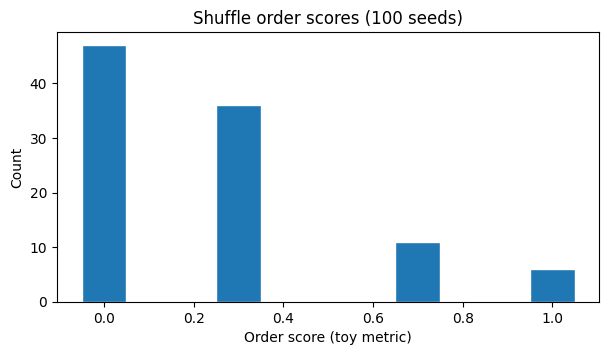

평균: 0.253


In [8]:
# TODO ⑦: seed=0~99의 shuffle 점수 계산
shuffle_scores = [order_score(shuffle_steps(example, seed=seed)) for seed in range(100)]
plt.figure(figsize=(7, 3.5))
plt.hist(shuffle_scores, bins=np.linspace(-0.05, 1.05, 12), edgecolor='white')
plt.xlabel('Order score (toy metric)')
plt.ylabel('Count')
plt.title('Shuffle order scores (100 seeds)')
plt.show()
print('평균:', round(float(np.mean(shuffle_scores)), 3))
assert len(shuffle_scores) == 100

### 문제 3-2. 결과 해석

1. `wrong_final`과 `shuffled`의 점수는 어떻게 달랐나요? 이 점수가 측정하는 것이 무엇인지 함께 쓰세요.
2. 이 실험만으로 **LLM도 순서를 섞으면 실제 수학 정답률이 떨어진다**고 말할 수 있나요? 이유를 쓰세요.

**답:**

1. `wrong_final`은 Thought의 단계 순서를 바꾸지 않으므로 순서 점수가 1.0으로 유지됩니다. 반면 `shuffled`는 단계 순서가 섞여 점수가 낮아질 수 있습니다. 이 점수는 인접한 단계의 ID가 `0 → 1 → 2 → 3`처럼 연속적으로 이어지는 비율을 측정하는 실습용 구조 지표입니다.
2. 말할 수 없습니다. 이 실험은 작은 예시의 단계 ID 순서만 측정했으며 실제 LLM을 학습하거나 수학 문제의 정답률을 평가하지 않았습니다. LLM의 실제 정확도 변화에 대한 결론은 논문의 별도 학습·평가 실험을 근거로 해야 합니다.

## Part 4. 논문 Figure 2와 Table 3 읽기

아래 수치는 **논문에서 보고한 결과를 옮긴 것**이며, 위의 실습용 `order_score`와 다릅니다.

- Figure 2 / §4.2: QwQ에서 선별한 4,618개 정답 응답 등을 활용한 통제 실험. 평균은 **4개 수학 벤치마크** 기준입니다.
- Table 3 / §5.5: Short CoT와 Long CoT의 학습 결과를 비교합니다.

숫자를 읽을 때는 **학습 전(Original)**, **정상 데이터로 SFT한 뒤(Correct)**, **교란 데이터로 SFT한 뒤**를 구분하세요.

,학습 조건,평균 정확도 (%)
0,학습 전 모델,56.7
1,정상 데이터,66.3
2,최종 오답 데이터,63.1
3,숫자 70% 손상,62.0
4,추론 키워드 문장 100% 제거,63.0


/tmp/ipykernel_1362/2995775301.py:12: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1362/2995775301.py:12: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1362/2995775301.py:12: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1362/2995775301.py:12: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1362/2995775301.py:12: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1362/2995775301.py:12: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1362/2995775301.py:12: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tig

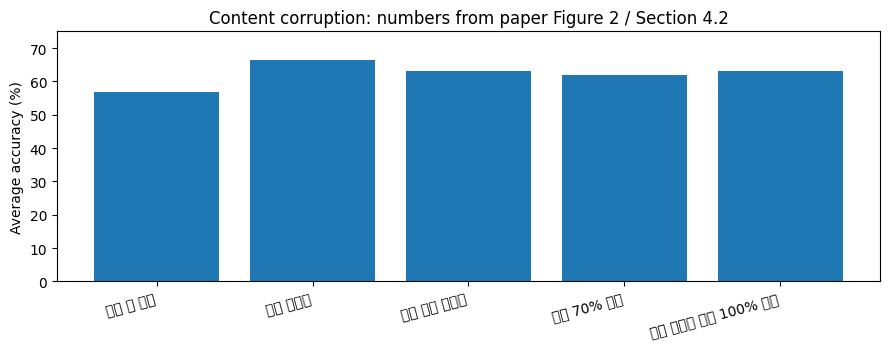

In [9]:
content_results = pd.DataFrame({
    '학습 조건': ['학습 전 모델', '정상 데이터', '최종 오답 데이터', '숫자 70% 손상', '추론 키워드 문장 100% 제거'],
    '평균 정확도 (%)': [56.7, 66.3, 63.1, 62.0, 63.0]
})
display(content_results)
plt.figure(figsize=(9, 3.6))
plt.bar(content_results['학습 조건'], content_results['평균 정확도 (%)'])
plt.ylim(0, 75)
plt.ylabel('Average accuracy (%)')
plt.xticks(rotation=15, ha='right')
plt.title('Content corruption: numbers from paper Figure 2 / Section 4.2')
plt.tight_layout()
plt.show()

### 문제 4-1. Accuracy 계산

오답 데이터 학습 모델의 정확도가 학습 전 모델보다 몇 **%p** 높은지, 정상 데이터 학습 모델보다는 몇 **%p** 낮은지 계산하세요. `%`와 `%p`를 구분해 쓰세요.

In [10]:
base_acc = 56.7
correct_acc = 66.3
wrong_acc = 63.1
# TODO ⑧ / ⑨
improvement_over_base = wrong_acc - base_acc
gap_to_correct = correct_acc - wrong_acc
print(f'학습 전 대비: +{improvement_over_base:.1f}%p')
print(f'정상 데이터 대비: -{gap_to_correct:.1f}%p')
assert np.isclose(improvement_over_base, 6.4)
assert np.isclose(gap_to_correct, 3.2)

학습 전 대비: +6.4%p
정상 데이터 대비: -3.2%p


In [11]:
cot_table = pd.DataFrame({
    'Benchmark': ['MATH-500', 'AMC 2023', 'OlympiadBench', 'AIME 2024'],
    'Original': [84.8, 67.5, 47.6, 16.7],
    'Short CoT': [70.4, 55.0, 36.4, 13.3],
    'Long CoT': [89.2, 77.5, 58.5, 40.0]
})
# TODO ⑩: Long CoT와 Short CoT 정확도의 차이 (%p)
cot_table['Long - Short (%p)'] = cot_table['Long CoT'] - cot_table['Short CoT']
display(cot_table)
assert np.isclose(cot_table.loc[3, 'Long - Short (%p)'], 26.7)

,Benchmark,Original,Short CoT,Long CoT,Long - Short (%p)
0,MATH-500,84.8,70.4,89.2,18.8
1,AMC 2023,67.5,55.0,77.5,22.5
2,OlympiadBench,47.6,36.4,58.5,22.1
3,AIME 2024,16.7,13.3,40.0,26.7


### 문제 4-2. 논문 결과 해석 (서술형)

1. **최종 오답 데이터**로 학습한 모델의 평균 정확도가 63.1%라는 사실이, “정확한 정답 데이터는 필요 없다”는 주장까지 뒷받침하나요?
2. **순서 변경 실험**에서 정확도가 떨어졌다는 사실과, “모델이 내부적으로 인간처럼 추론하는 법을 배웠다”는 주장은 어떻게 다른가요?
3. Table 3에서 AIME 2024의 `Long CoT − Short CoT` 정확도 차이와 `Long CoT − Original` 차이를 각각 적으세요.

**답:**

1. 뒷받침하지 않습니다. 최종 오답 데이터로 학습한 모델이 학습 전보다 6.4%p 높았지만 정상 데이터로 학습한 66.3%보다는 3.2%p 낮았습니다. 따라서 오답이 포함된 추론 데이터에서도 학습 효과가 나타날 수 있다는 결과이지, 정확한 정답 데이터가 불필요하다는 뜻은 아닙니다.
2. 순서 변경으로 성능이 떨어졌다는 결과는 학습 데이터의 추론 구조와 단계 간 연결성이 성능에 중요하다는 경험적 증거입니다. 그러나 이것만으로 모델의 내부 계산 과정이 인간의 사고 과정과 동일하거나 인간처럼 추론하는 법을 배웠다고 결론 내릴 수는 없습니다.
3. AIME 2024에서 `Long CoT − Short CoT`는 40.0 − 13.3 = 26.7%p이고, `Long CoT − Original`은 40.0 − 16.7 = 23.3%p입니다.

## Part 5. 논문을 읽고 생각해보기

**5-1.** 이 논문에서 새로운 모델 구조나 학습 손실을 제안했나요? 기존의 **SFT / LoRA**를 활용해 주로 무엇을 검증했는지 적으세요. (§3~4)

**답:**

새로운 모델 구조나 학습 손실을 제안하는 것이 핵심은 아닙니다. 기존 SFT와 LoRA를 이용해 Long CoT 시연 데이터로 학습했을 때 추론 성능이 향상되는지, 그리고 그 효과가 정답의 정확한 내용 자체보다 추론의 구조와 일관성에 얼마나 의존하는지를 여러 데이터 교란 실험으로 검증했습니다.

**5-2.** 논문 §4.2.2의 삭제·삽입·순서 변경 중, **추론 길이 감소**라는 혼란 요인을 가장 직접적으로 줄여 주는 실험은 무엇인가요? 이유도 적으세요.

**답:**

순서 변경(shuffle) 실험입니다. 기존 추론 단계들을 삭제하지 않고 그대로 유지한 채 배열 순서만 바꾸므로 전체 단계 수와 정보량을 거의 유지할 수 있습니다. 따라서 성능 변화가 단순히 추론이 짧아져서 생긴 것인지와 단계 순서가 무너져서 생긴 것인지를 더 직접적으로 구분할 수 있습니다.

**5-3.** 논문에서 보여준 결과 **두 가지**와, 이번 CPU 실습만으로 확인할 수 **없는 것 한 가지**를 적으세요.

**답:**

논문은 첫째, 최종 오답이나 숫자 손상처럼 내용이 부정확한 Long CoT 데이터로 학습해도 학습 전 모델보다 성능이 향상될 수 있음을 보였습니다. 둘째, 추론 단계의 삭제·삽입·순서 변경처럼 구조를 교란하면 성능이 더 크게 저하되어 추론 구조의 일관성이 중요함을 보였습니다. 반면 이번 CPU 실습은 단순한 `order_score`를 계산하는 예시이므로, 실제 대규모 LLM을 교란 데이터로 SFT한 뒤 수학 벤치마크 정확도가 어떻게 변하는지는 직접 확인할 수 없습니다.


## 선택 심화 — 공식 구현 살펴보기

공식 저장소에는 데이터 정제, 학습(LLaMA-Factory 활용), 평가 관련 코드가 공개되어 있습니다. GPU/대용량 모델을 내려받을 필요는 없습니다.

- [SkyThought GitHub](https://github.com/NovaSky-AI/SkyThought)
- [논문 원문 (ACL Anthology)](https://aclanthology.org/2025.findings-emnlp.866/)

**선택 질문:** GitHub에서 `recipes`, `skythought/train`, `skythought/evals` 중 한 곳을 골라 파일이나 README를 읽고, 전체 파이프라인에서 어떤 역할인지 2~3문장으로 설명해 보세요.

**답:**

> 주의: 공개된 SkyThought 저장소는 관련 학습·평가 구현을 제공하지만, 이 노트북의 단순 데이터 교란 함수가 논문 저자의 원본 구조 교란 스크립트를 그대로 복사한 것은 아닙니다.

## 제출 전 확인

- `TODO ①~⑩`을 모두 채웠는지 확인하기
- 모든 코드 셀을 위에서부터 실행한 뒤 오류가 없는지 확인하기
- 문제 1-2, 2-3, 3-2, 4-2, 5-1~5-3의 서술형 답변 작성하기
- 결과 그래프/표가 보이도록 `.ipynb`로 저장하기

**주요 참고**: Li et al. (2025), §3–5, Figure 2·4, Table 3; NovaSky-AI/SkyThought 공식 저장소.